In [26]:
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split
from IPython.display import Image
from imutils import paths
import numpy as np
import cv2
import os

In [27]:
def extract_histogram(image, bins = (8,8,8)):
    hist = cv2.calcHist([image], [0,1,2], None, bins, [0, 256, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

In [28]:
imagePaths = sorted(list(paths.list_images('train')))
data = []
labels = []

for i, imagePath in enumerate(imagePaths):
    image = cv2.imread(imagePath, 1)
    label = imagePath.split(os.path.sep)[-1].split(".")[0]
    hist = extract_histogram(image)
    data.append(hist)
    labels.append(label)


0


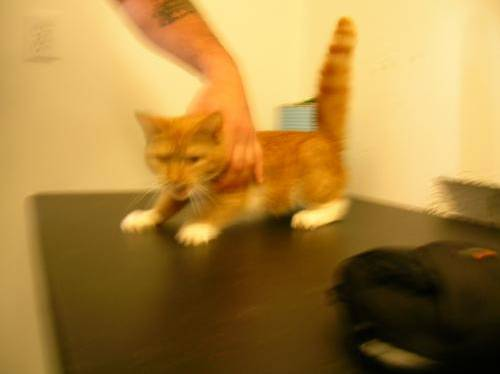

In [29]:
le = LabelEncoder()
labels = le.fit_transform(labels)
print(labels[0])
Image(filename=imagePaths[0])

In [30]:
trainData, testData, trainLabels, testLabels = train_test_split(np.array(data), labels, test_size=0.25, random_state=2)

In [31]:
model = LinearSVC(random_state=2, C = 0.94)
model.fit(trainData, trainLabels)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.94
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",2
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adj

In [38]:
predictions = model.predict(testData)
print(classification_report(testLabels, predictions, target_names=le.classes_))
d = f1_score(testLabels, predictions, average='macro')
d

              precision    recall  f1-score   support

         cat       0.56      0.72      0.63       121
         dog       0.65      0.48      0.55       129

    accuracy                           0.60       250
   macro avg       0.61      0.60      0.59       250
weighted avg       0.61      0.60      0.59       250



0.591919191919192

In [33]:
model.coef_[0][1]

np.float64(-0.08853579974854407)

[0]


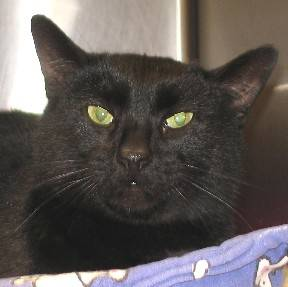

In [34]:
singleImage = cv2.imread('test/cat.1016.jpg')
histt = extract_histogram(singleImage)
histt2 = histt.reshape(1, -1)
predictions = model.predict(histt2)
print(predictions)
Image(filename='test/cat.1016.jpg')

### Ответы

In [39]:
a = model.coef_[0][280]
b = model.coef_[0][129]
c = model.coef_[0][440]
print(a,b,c,d)

0.2031764427646431 0.008616754963544497 0.0 0.591919191919192


## Следующее задание

In [40]:
import pandas as pd
import numpy as np
import math

# 1. Создаем датасет на основе картинок
data = [
    ('Pizza', 1, 3, 'No'),
    ('Pizza', 5, 5, 'Yes'),
    ('Pizza', 5, 4, 'Yes'),
    ('Sushi', 1, 3, 'Yes'),
    ('Sushi', 5, 5, 'No'),
    ('Sushi', 4, 2, 'Yes'),
    ('Sushi', 4, 4, 'No'),
    ('Sushi', 5, 5, 'Yes'),
    ('Sushi', 3, 3, 'Yes'),
    ('Sushi', 3, 3, 'No'),
    ('Sushi', 4, 2, 'Yes'),
    ('Burgers', 5, 5, 'Yes'),
    ('Burgers', 4, 4, 'Yes'),
    ('Burgers', 3, 3, 'Yes'),
    ('Burgers', 2, 2, 'Yes'),
    ('Burgers', 1, 1, 'Yes'),
    ('Burgers', 2, 2, 'No'),
    ('Burgers', 1, 1, 'No')
]

df = pd.DataFrame(data, columns=['Food', 'Price', 'Taste', 'Demand'])

# Функция для расчета энтропии
def calc_entropy(series):
    probs = series.value_counts(normalize=True)
    return -sum(p * math.log2(p) for p in probs if p > 0)

# --- 1. Начальная энтропия отклика H(Demand) ---
h_demand = calc_entropy(df['Demand'])
print(f"1. Начальная энтропия H(Demand): {h_demand:.3f}")

# --- 2. Таблицы условных вероятностей P(Demand|Feature) ---
print("\n2. Условные вероятности P(Demand|Feature):")
for feature in ['Food', 'Price', 'Taste']:
    print(f"\nПризнак: {feature}")
    # Считаем количество Yes и No для каждого значения признака
    ct = pd.crosstab(df[feature], df['Demand'])
    # Превращаем в вероятности (делим на общее количество в строке)
    prob_table = ct.div(ct.sum(axis=1), axis=0)
    print(prob_table.round(3))

# --- 3. Условные энтропии H(Demand|Food), H(Demand|Price), H(Demand|Taste) ---
def calc_conditional_entropy(df, feature, target='Demand'):
    total_entropy = 0
    total_count = len(df)
    
    for val in df[feature].unique():
        subset = df[df[feature] == val]
        weight = len(subset) / total_count
        entropy = calc_entropy(subset[target])
        total_entropy += weight * entropy
    return total_entropy

h_food = calc_conditional_entropy(df, 'Food')
h_price = calc_conditional_entropy(df, 'Price')
h_taste = calc_conditional_entropy(df, 'Taste')

print(f"\n3. Условные энтропии:")
print(f"H(Demand|Food)  = {h_food:.3f}")
print(f"H(Demand|Price) = {h_price:.3f}")
print(f"H(Demand|Taste) = {h_taste:.3f}")

# --- 4, 5, 6. Прирост информации IG(Demand|Feature) ---
ig_food = h_demand - h_food
ig_price = h_demand - h_price
ig_taste = h_demand - h_taste

print(f"\n4. Прирост информации IG(Demand|Food):  {ig_food:.3f}")
print(f"5. Прирост информации IG(Demand|Price): {ig_price:.3f}")
print(f"6. Прирост информации IG(Demand|Taste): {ig_taste:.3f}")

1. Начальная энтропия H(Demand): 0.918

2. Условные вероятности P(Demand|Feature):

Признак: Food
Demand      No    Yes
Food                 
Burgers  0.286  0.714
Pizza    0.333  0.667
Sushi    0.375  0.625

Признак: Price
Demand     No    Yes
Price               
1       0.500  0.500
2       0.500  0.500
3       0.333  0.667
4       0.250  0.750
5       0.200  0.800

Признак: Taste
Demand     No    Yes
Taste               
1       0.500  0.500
2       0.250  0.750
3       0.400  0.600
4       0.333  0.667
5       0.250  0.750

3. Условные энтропии:
H(Demand|Food)  = 0.913
H(Demand|Price) = 0.867
H(Demand|Taste) = 0.894

4. Прирост информации IG(Demand|Food):  0.005
5. Прирост информации IG(Demand|Price): 0.051
6. Прирост информации IG(Demand|Taste): 0.024
